<a href="https://colab.research.google.com/github/LexieLyu37/also-cracker/blob/main/06_ML_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CID: 02392139
Username: kl3323

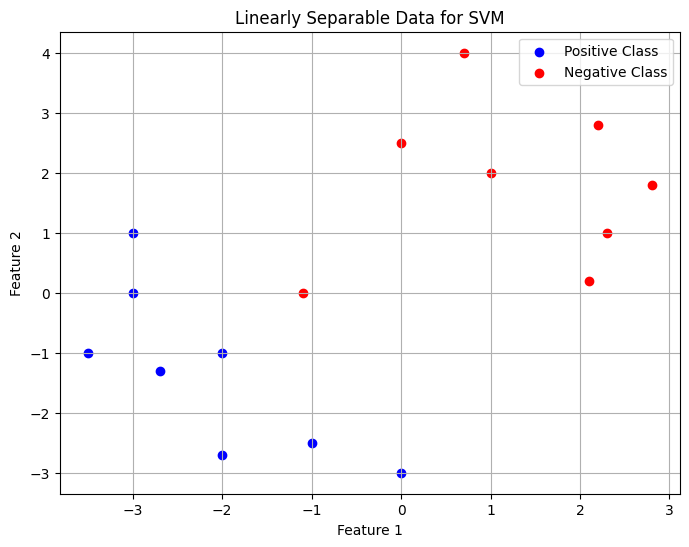

In [44]:
# Create linearly separable data

import numpy as np
import matplotlib.pyplot as plt

# Generate positive class samples
X_positive = np.array([[-3.5, -1], [-3, 0], [-3, 1], [-2.7, -1.3], [-2, -1], [-2, -2.7],
                       [-1, -2.5], [0, -3]])
y_positive = np.ones(len(X_positive))

# Generate negative class samples
X_negative = np.array([[-1.1, 0], [0, 2.5], [1, 2], [0.7, 4],
                       [2.1, 0.2], [2.3, 1], [2.8, 1.8], [2.2, 2.8]])
y_negative = -np.ones(len(X_negative))

# Concatenate positive and negative samples
X = np.vstack((X_positive, X_negative))
y = np.concatenate((y_positive, y_negative))

# Plotting
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], marker='o', label='Positive Class', color='blue')
plt.scatter(X[y == -1][:, 0], X[y == -1][:, 1], marker='o', label='Negative Class', color='red')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Linearly Separable Data for SVM')
plt.legend()
plt.grid()
plt.show()

In [45]:
import cvxpy as cp


def hard_margin(X, y):
    m, n = X.shape

    # Define the SVM optimization problem
    W = cp.Variable(n, value=np.zeros(n))  # Weights
    b = cp.Variable(value=0)               # Bias
    objective = cp.Minimize(0.5 * cp.square(cp.norm(W)))
    constraints = [y[i] * (X[i] @ W + b)  >= 1 for i in range(m)]  # Margin constraints

    # Formulate and solve the SVM problem
    prob = cp.Problem(objective, constraints)
    prob.solve()

    # Check if the problem was solved successfully
    if prob.status != cp.OPTIMAL:
        print("SVM optimization failed. Please check the data and constraints.")
        return

    # Get the optimal values of W and b
    W_optimal = W.value
    b_optimal = b.value
    print("Optimal value of W:", W_optimal)
    print("Optimal value of b:", b_optimal)

    # Calculate the slope and intercept of the decision boundary
    slope = -W_optimal[0] / W_optimal[1]
    intercept = -b_optimal / W_optimal[1]

    # Calculate the support vectors
    alphas = np.array([constraints[i].dual_value for i in range(m)])  # Extract alphas corresponding to support vectors
    non_zero_alphas = alphas[np.where(alphas > 1e-4)] # Due to approximations you may get too small values for alpha instead of zero. We will consider values below 1e-4 as zero for alpha.
    support_vectors = X[np.where(alphas > 1e-4)]  # Choose support vectors with non-zero dual values
    #print(alphas)
    print("Non_zero aplhas:", non_zero_alphas)
    print("Support Vectors:\n", support_vectors)


    # Plot the data points and decision boundary
    #plt.figure(figsize=(8, 6))
    plt.scatter(X[:, 0], X[:, 1], c=y)
    x_vals = np.array([np.min(X[:, 0]) - 1, np.max(X[:, 0]) + 1])
    y_vals = slope * x_vals + intercept
    plt.plot(x_vals, y_vals, label='Decision Boundary', color='black')

    # Plot the support vectors
    margin = 1 / W_optimal[1]
    y_down = y_vals - margin
    y_up = y_vals + margin
    plt.plot(x_vals, y_down, linestyle='dotted', color='grey')
    plt.plot(x_vals, y_up, linestyle='dotted', color='grey')
    plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=80, facecolors='none', edgecolors='r', label='Support Vectors')

    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()
    plt.title('Hard Margin SVM Decision Boundary')
    plt.grid()
    plt.show()

Optimal value of W: [-1.73913043 -1.30434783]
Optimal value of b: -2.913043478293933
Non_zero aplhas: [1.44612493 0.91682403 2.36294896]
Support Vectors:
 [[-3.   1. ]
 [ 0.  -3. ]
 [-1.1  0. ]]


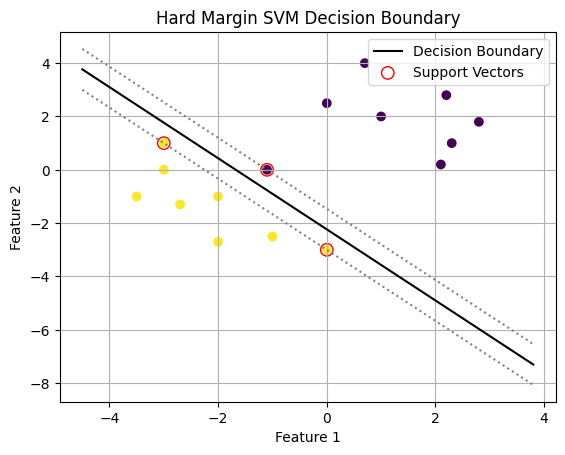

In [46]:
hard_margin(X, y)

Optimal value of W: [-2.67874166e-05 -5.00000001e-01]
Optimal value of b: -2.678732450621305e-05
Non_zero aplhas: [0.12498982 0.125     ]
Support Vectors:
 [[-1.  2.]
 [-1. -2.]]


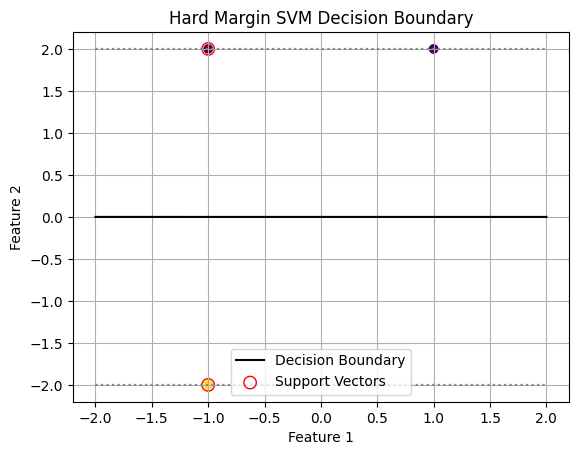

In [47]:
# Task 1
X_exam = np.array([
    [1, 2],
    [-1, 2],
    [-1, -2]
], dtype=float)

y_exam = np.array([-1, -1, 1], dtype=float)

hard_margin(X_exam, y_exam)

The hard-margin SVM result agrees with the exam solution.
The optimal values are approximately:
W = (0, -0.5)
b = 0
The non-zero dual values are approximately 1/8 and 1/8.
The support vectors are (-1, 2) and (-1, -2).
The point (1, 2) is not a support vector because its alpha value is zero.
The decision boundary is x2 = 0.
The small difference between 0.12498982 and 0.125 is caused by numerical precision.

Solving C = 0.001 ...
Status: optimal
Optimal W: [-0.0272 -0.0248]
Optimal b: -0.005527106043269116
Number of support vectors: 16
Margin width: 54.33498853831964
Non-zero alphas: [0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001
 0.001 0.001 0.001 0.001]
Support vectors:
[[-3.5 -1. ]
 [-3.   0. ]
 [-3.   1. ]
 [-2.7 -1.3]
 [-2.  -1. ]
 [-2.  -2.7]
 [-1.  -2.5]
 [ 0.  -3. ]
 [-1.1  0. ]
 [ 0.   2.5]
 [ 1.   2. ]
 [ 0.7  4. ]
 [ 2.1  0.2]
 [ 2.3  1. ]
 [ 2.8  1.8]
 [ 2.2  2.8]]
Slack variables: [0.88552711 0.92392711 0.94872711 0.89984711 0.92632711 0.88416711
 0.91632711 0.93112711 1.02439289 0.93247289 0.91767289 0.87623289
 0.93239289 0.90711289 0.87367289 0.86519289]


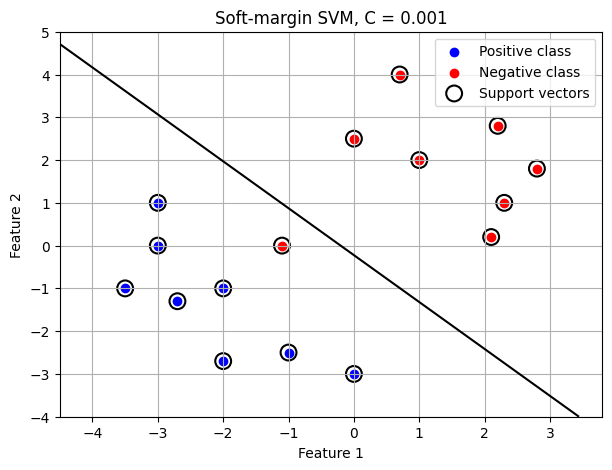

Solving C = 0.1 ...
Status: optimal
Optimal W: [-0.38493724 -0.35146444]
Optimal b: -0.12133890393740576
Number of support vectors: 6
Margin width: 3.8369137446828083
Non-zero alphas: [0.1        0.02020342 0.1        0.1        0.04661753 0.07358589]
Support vectors:
[[-3.   1. ]
 [-2.  -1. ]
 [ 0.  -3. ]
 [-1.1  0. ]
 [ 0.   2.5]
 [ 2.1  0.2]]
Slack variables: [0.00000000e+00 0.00000000e+00 3.17991625e-01 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 6.69455876e-02
 1.30209206e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 5.46170743e-09 0.00000000e+00 0.00000000e+00 0.00000000e+00]


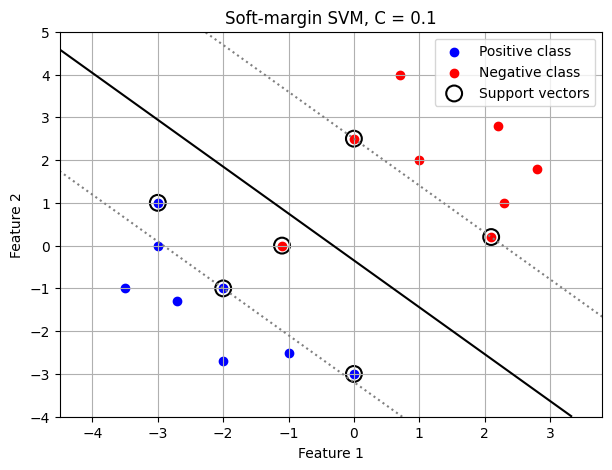

Solving C = 1 ...
Status: optimal
Optimal W: [-0.73599999 -0.552     ]
Optimal b: -0.6559999931107822
Number of support vectors: 3
Margin width: 2.1739130569475242
Non-zero alphas: [0.612 0.388 1.   ]
Support vectors:
[[-3.   1. ]
 [ 0.  -3. ]
 [-1.1  0. ]]
Slack variables: [0.00000000e+00 0.00000000e+00 8.05751118e-09 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 2.23230360e-09
 1.15360000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]


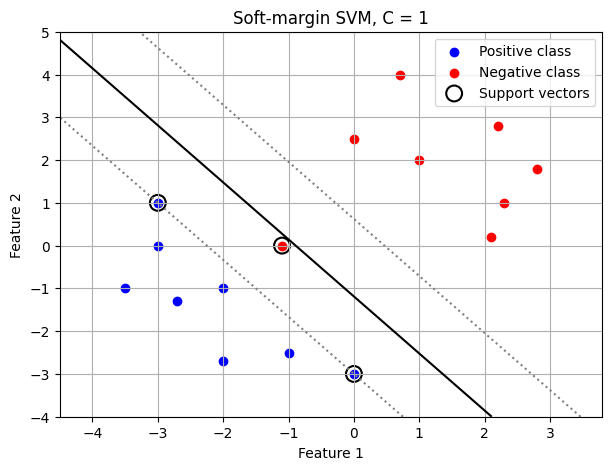

Solving C = 100.0 ...
Status: optimal
Optimal W: [-1.73913044 -1.30434783]
Optimal b: -2.913043481580955
Number of support vectors: 3
Margin width: 0.9199999987920418
Non-zero alphas: [1.44612476 0.91682419 2.36294896]
Support vectors:
[[-3.   1. ]
 [ 0.  -3. ]
 [-1.1  0. ]]
Slack variables: [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 1.55918882e-12 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]


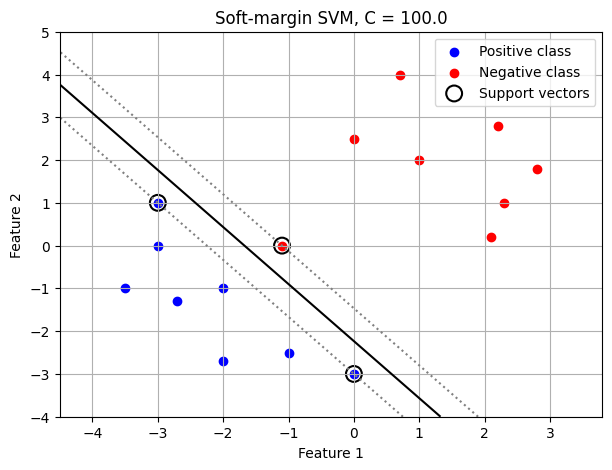

Solving C = 100000.0 ...
Status: optimal
Optimal W: [-1.73913043 -1.30434783]
Optimal b: -2.9130434784253265
Number of support vectors: 3
Margin width: 0.9199999999389834
Non-zero alphas: [1.44612476 0.9168242  2.36294896]
Support vectors:
[[-3.   1. ]
 [ 0.  -3. ]
 [-1.1  0. ]]
Slack variables: [1.10696928e-15 1.18142056e-15 1.09938109e-15 1.16923406e-15
 1.31288199e-15 1.11864446e-15 1.23125224e-15 1.12676198e-15
 6.76839115e-16 1.17344985e-15 1.35621690e-15 1.05047143e-15
 1.21976357e-15 1.18908635e-15 1.00015370e-15 9.29842441e-16]


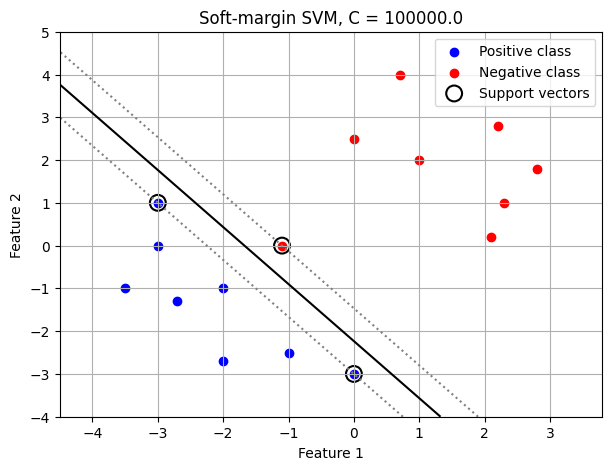


Summary
C	Number of support vectors	Margin width	W	b
0.001	16	54.334989	[-0.0272 -0.0248]	-0.005527
0.1	6	3.836914	[-0.38493724 -0.35146444]	-0.121339
1	3	2.173913	[-0.73599999 -0.552     ]	-0.656000
100.0	3	0.920000	[-1.73913044 -1.30434783]	-2.913043
100000.0	3	0.920000	[-1.73913043 -1.30434783]	-2.913043


In [48]:
# Task 2
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt


def solve_cvxpy(problem):
    """Solve the convex problem with a reliable solver and a fallback."""
    try:
        problem.solve(solver=cp.CLARABEL, verbose=False)
    except Exception:
        problem.solve(
            solver=cp.SCS,
            eps=1e-5,
            max_iters=100000,
            verbose=False
        )

    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f"Solver failed with status: {problem.status}")


def soft_margin(X_data, y_data, C):
    """Train and plot a soft-margin linear SVM for one C value."""
    X_data = np.asarray(X_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    m, n = X_data.shape

    W = cp.Variable(n)
    b = cp.Variable()
    xi = cp.Variable(m, nonneg=True)

    constraints = [
        y_data[i] * (X_data[i] @ W + b) >= 1 - xi[i]
        for i in range(m)
    ]

    objective = cp.Minimize(
        0.5 * cp.sum_squares(W) + C * cp.sum(xi)
    )
    problem = cp.Problem(objective, constraints)

    print(f"Solving C = {C} ...")
    solve_cvxpy(problem)

    W_opt = np.asarray(W.value).reshape(-1)
    b_opt = float(b.value)
    xi_opt = np.asarray(xi.value).reshape(-1)

    alphas = np.array([
        float(constraint.dual_value)
        for constraint in constraints
    ])

    support_mask = alphas > 1e-5
    support_vectors = X_data[support_mask]
    support_alphas = alphas[support_mask]

    norm_W = np.linalg.norm(W_opt)
    margin_width = 2.0 / norm_W if norm_W > 1e-12 else np.inf

    print("Status:", problem.status)
    print("Optimal W:", W_opt)
    print("Optimal b:", b_opt)
    print("Number of support vectors:", support_vectors.shape[0])
    print("Margin width:", margin_width)
    print("Non-zero alphas:", support_alphas)
    print("Support vectors:")
    print(support_vectors)
    print("Slack variables:", xi_opt)

    plt.figure(figsize=(7, 5))
    plt.scatter(
        X_data[y_data == 1, 0], X_data[y_data == 1, 1],
        color="blue", marker="o", label="Positive class"
    )
    plt.scatter(
        X_data[y_data == -1, 0], X_data[y_data == -1, 1],
        color="red", marker="o", label="Negative class"
    )

    if len(support_vectors) > 0:
        plt.scatter(
            support_vectors[:, 0], support_vectors[:, 1],
            s=130, facecolors="none", edgecolors="black",
            linewidths=1.5, label="Support vectors"
        )

    x_min = X_data[:, 0].min() - 1
    x_max = X_data[:, 0].max() + 1
    y_min = X_data[:, 1].min() - 1
    y_max = X_data[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    decision = W_opt[0] * xx + W_opt[1] * yy + b_opt
    plt.contour(
        xx, yy, decision,
        levels=[-1, 0, 1],
        colors=["grey", "black", "grey"],
        linestyles=["dotted", "solid", "dotted"]
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(f"Soft-margin SVM, C = {C}")
    plt.legend()
    plt.grid(True)
    plt.show()

    return {
        "C": C,
        "W": W_opt,
        "b": b_opt,
        "alphas": alphas,
        "support_vectors": support_vectors,
        "support_alphas": support_alphas,
        "slack": xi_opt,
        "margin_width": margin_width,
        "status": problem.status
    }

C_values = [1e-3, 1e-1, 1, 1e2, 1e5]

soft_margin_results = {}

for C in C_values:
    soft_margin_results[C] = soft_margin(X, y, C)

print("\nSummary")
print("C\tNumber of support vectors\tMargin width\tW\tb")
for C, result in soft_margin_results.items():
    print(
        f"{C}\t"
        f"{len(result['support_vectors'])}\t"
        f"{result['margin_width']:.6f}\t"
        f"{result['W']}\t"
        f"{result['b']:.6f}"
    )


When C is very small, the model allows more classification errors.
It chooses a wider margin and has more support vectors.

When C increases, classification errors are penalised more strongly.
The margin becomes narrower and the number of support vectors decreases.

For C = 100 and C = 100000, the results are almost the same as the hard-margin SVM.
For this dataset, large C values give a strict separating boundary.


Soft-margin SVM, C = 0.001
W: [-0.0272 -0.0248]
b: 0.003959999680519022
Number of support vectors: 16
Margin width: 54.33498852303893
Support vectors:
[[-1.1  0. ]
 [ 0.   2.5]
 [ 1.   2. ]
 [ 0.7  4. ]
 [ 2.1  0.2]
 [ 2.3  1. ]
 [ 2.8  1.8]
 [ 2.2  2.8]
 [-3.5 -1. ]
 [-3.   0. ]
 [-3.   1. ]
 [-2.7 -1.3]
 [-2.  -1. ]
 [-2.  -2.7]
 [-1.  -2.5]
 [ 0.  -3. ]]


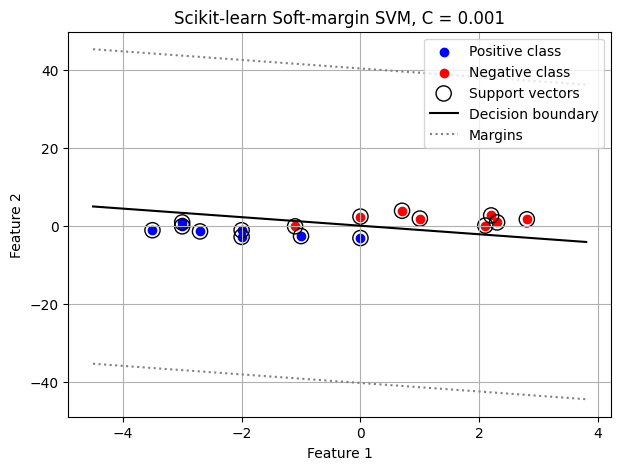


Soft-margin SVM, C = 0.1
W: [-0.3847726  -0.35131411]
b: -0.1214295895208465
Number of support vectors: 6
Margin width: 3.838555519104225
Support vectors:
[[-1.1  0. ]
 [ 0.   2.5]
 [ 2.1  0.2]
 [-3.   1. ]
 [-2.  -1. ]
 [ 0.  -3. ]]


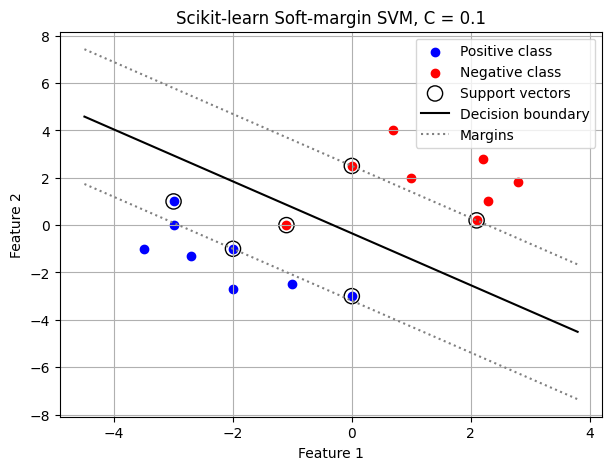


Soft-margin SVM, C = 1
W: [-0.73599999 -0.55200001]
b: -0.6560000228881836
Number of support vectors: 3
Margin width: 2.1739130434782608
Support vectors:
[[-1.1  0. ]
 [-3.   1. ]
 [ 0.  -3. ]]


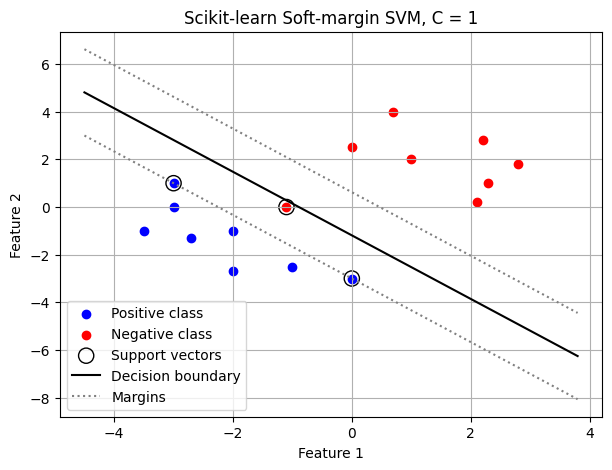


Soft-margin SVM, C = 100.0
W: [-1.73838548 -1.30378914]
b: -2.9116528947672458
Number of support vectors: 3
Margin width: 0.920394244087651
Support vectors:
[[-1.1  0. ]
 [-3.   1. ]
 [ 0.  -3. ]]


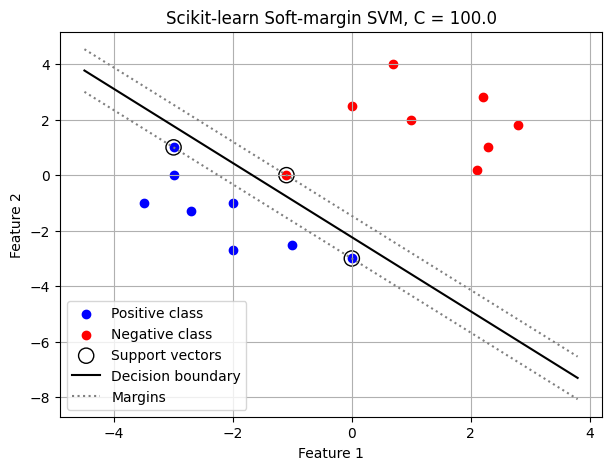


Soft-margin SVM, C = 100000.0
W: [-1.73838548 -1.30378914]
b: -2.9116528947672458
Number of support vectors: 3
Margin width: 0.920394244087651
Support vectors:
[[-1.1  0. ]
 [-3.   1. ]
 [ 0.  -3. ]]


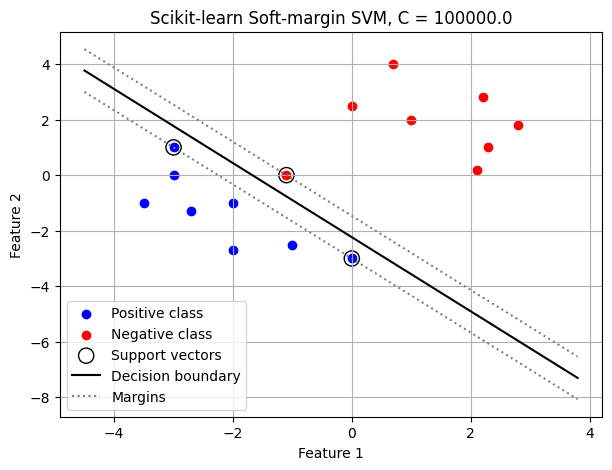

In [49]:
# Task 3 (soft margin)

from sklearn.svm import SVC

C_values_sklearn = [1e-3, 1e-1, 1, 1e2, 1e5]

def plot_svm_model(model, X, y, title):
    W = model.coef_[0]
    b = model.intercept_[0]

    x_values = np.linspace(
        X[:, 0].min() - 1,
        X[:, 0].max() + 1,
        300
    )

    decision_boundary = -(W[0] * x_values + b) / W[1]
    upper_margin = -(W[0] * x_values + b - 1) / W[1]
    lower_margin = -(W[0] * x_values + b + 1) / W[1]

    plt.figure(figsize=(7, 5))

    plt.scatter(X[y == 1, 0], X[y == 1, 1],
                color="blue", label="Positive class")
    plt.scatter(X[y == -1, 0], X[y == -1, 1],
                color="red", label="Negative class")

    support_vectors = model.support_vectors_

    plt.scatter(
        support_vectors[:, 0],
        support_vectors[:, 1],
        s=120,
        facecolors="none",
        edgecolors="black",
        label="Support vectors"
    )

    plt.plot(x_values, decision_boundary,
             color="black", label="Decision boundary")
    plt.plot(x_values, upper_margin,
             color="grey", linestyle="dotted", label="Margins")
    plt.plot(x_values, lower_margin,
             color="grey", linestyle="dotted")

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


for C in C_values_sklearn:
    model = SVC(kernel="linear", C=C)
    model.fit(X, y)

    W = model.coef_[0]
    b = model.intercept_[0]
    margin_width = 2 / np.linalg.norm(W)

    print(f"\nSoft-margin SVM, C = {C}")
    print("W:", W)
    print("b:", b)
    print("Number of support vectors:", len(model.support_vectors_))
    print("Margin width:", margin_width)
    print("Support vectors:")
    print(model.support_vectors_)

    plot_svm_model(
        model,
        X,
        y,
        f"Scikit-learn Soft-margin SVM, C = {C}"
    )

Hard-margin SVM
W: [-1.73838548 -1.30378914]
b: -2.9116528947672458
Number of support vectors: 3
Margin width: 0.920394244087651
Support vectors:
[[-1.1  0. ]
 [-3.   1. ]
 [ 0.  -3. ]]


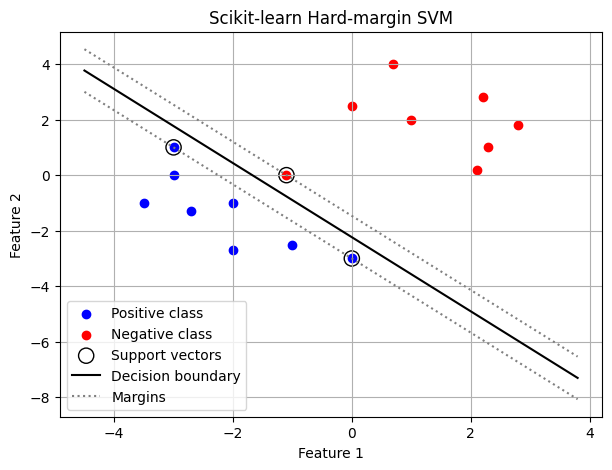

In [50]:
# Task 3 (hard margin)

hard_model = SVC(
    kernel="linear",
    C=1e5
)

hard_model.fit(X, y)

W_hard = hard_model.coef_[0]
b_hard = hard_model.intercept_[0]
margin_width_hard = 2 / np.linalg.norm(W_hard)

print("Hard-margin SVM")
print("W:", W_hard)
print("b:", b_hard)
print("Number of support vectors:", len(hard_model.support_vectors_))
print("Margin width:", margin_width_hard)
print("Support vectors:")
print(hard_model.support_vectors_)

plot_svm_model(
    hard_model,
    X,
    y,
    "Scikit-learn Hard-margin SVM"
)

Small C gives a wide margin and more support vectors.
Large C gives a narrower margin and fewer support vectors.
For large C, the result is close to the hard-margin SVM.